## import libraries

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from pathlib import Path
import joblib

In [2]:

# Step 69: Prepare the data for Linear Regression

project_dir = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
processed_dir = project_dir / "data" / "processed"

model_path = processed_dir / "nassau_candy_modeling_dataset.csv"
df_model = pd.read_csv(model_path)

# Input features
X = df_model[
    ["Ship Mode", "Product Name", "Current Factory", "Region"]
]

# Target to predict
y = df_model["Lead Time"]

print("Input shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(X.head())

print("\nTarget values:")
print(y.head())


Input shape: (10194, 4)
Target shape: (10194,)

Input features:
        Ship Mode                       Product Name  Current Factory  \
0  Standard Class         Wonka Bar - Milk Chocolate  Wicked Choccy's   
1  Standard Class  Wonka Bar - Triple Dazzle Caramel  Wicked Choccy's   
2  Standard Class  Wonka Bar - Nutty Crunch Surprise    Lot's O' Nuts   
3  Standard Class     Wonka Bar -Scrumdiddlyumptious    Lot's O' Nuts   
4  Standard Class  Wonka Bar - Triple Dazzle Caramel  Wicked Choccy's   

     Region  
0  Interior  
1  Interior  
2  Interior  
3  Interior  
4  Atlantic  

Target values:
0    5
1    5
2    5
3    5
4    8
Name: Lead Time, dtype: int64


## 2.Train-Test Split

In [3]:

# Step 70: Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training input:", X_train.shape)
print("Testing input:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training input: (8155, 4)
Testing input: (2039, 4)
Training target: (8155,)
Testing target: (2039,)


## 3. Build the Preprocessing Pipeline

In [4]:
# All four input features are categorical
categorical_features = [
    "Ship Mode",
    "Product Name",
    "Current Factory",
    "Region"
]

# Convert text categories into numerical columns
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

# Learn the encoding from training data only
X_train_encoded = preprocessor.fit_transform(X_train)

# Apply the same encoding to test data
X_test_encoded = preprocessor.transform(X_test)

print("Original training shape:", X_train.shape)
print("Encoded training shape:", X_train_encoded.shape)

print("\nOriginal testing shape:", X_test.shape)
print("Encoded testing shape:", X_test_encoded.shape)

print("\nPreprocessing pipeline created successfully.")

Original training shape: (8155, 4)
Encoded training shape: (8155, 28)

Original testing shape: (2039, 4)
Encoded testing shape: (2039, 28)

Preprocessing pipeline created successfully.


## 6. Compare Models and Select the Best Model

In [5]:
# 1. Define the models
models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

# 2. Train and evaluate every model
results = []
trained_models = {}

for name, model in models.items():
    print(f"Training {name}...")

    model.fit(X_train_encoded, y_train)

    predictions = model.predict(X_test_encoded)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    trained_models[name] = model

# 3. Create comparison table
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="MAE",
    ascending=True
).reset_index(drop=True)

print("\nMODEL COMPARISON")
print(results_df.round(3).to_string(index=False))

# 4. Select the model with the lowest MAE
best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]

print("\nBEST MODEL")
print("Selected model:", best_model_name)
print(f"MAE:  {results_df.loc[0, 'MAE']:.3f} days")
print(f"RMSE: {results_df.loc[0, 'RMSE']:.3f} days")
print(f"R2:   {results_df.loc[0, 'R2']:.3f}")

Training Linear Regression...
Training Random Forest...
Training Gradient Boosting...

MODEL COMPARISON
            Model   MAE  RMSE    R2
Gradient Boosting 0.923 1.105 0.622
    Random Forest 0.925 1.111 0.617
Linear Regression 0.926 1.105 0.621

BEST MODEL
Selected model: Gradient Boosting
MAE:  0.923 days
RMSE: 1.105 days
R2:   0.622


## 7. Cross-Validate the Models


In [7]:
# Step 76: Compare models using 5-fold cross-validation

import pandas as pd

from sklearn.model_selection import KFold, cross_validate
from sklearn.metrics import make_scorer, mean_absolute_error
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

models_cv = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []

for name, model in models_cv.items():
    scores = cross_validate(
        model,
        X_train_encoded,
        y_train,
        cv=cv,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        },
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean MAE": -scores["test_mae"].mean(),
        "MAE Std": scores["test_mae"].std(),
        "Mean RMSE": -scores["test_rmse"].mean(),
        "Mean R2": scores["test_r2"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)
cv_results_df = cv_results_df.sort_values(
    "Mean MAE"
).reset_index(drop=True)

print("5-FOLD CROSS-VALIDATION RESULTS")
print(cv_results_df.round(3).to_string(index=False))

5-FOLD CROSS-VALIDATION RESULTS
            Model  Mean MAE  MAE Std  Mean RMSE  Mean R2
Gradient Boosting     0.929    0.020      1.106    0.621
Linear Regression     0.931    0.019      1.105    0.621
    Random Forest     0.931    0.022      1.113    0.616


## 8. Save the Best Model


In [10]:
# Create the models directory in the project root
project_root = Path.cwd()

# If the notebook is running from the notebook folder,
# use its parent as the project root.
if project_root.name == "notebook":
    project_root = project_root.parent

models_dir = project_root / "models"
models_dir.mkdir(parents=True, exist_ok=True)

# Save the selected trained model
model_file = models_dir / "best_lead_time_model.joblib"
encoder_file = models_dir / "categorical_preprocessor.joblib"

joblib.dump(best_model, model_file)
joblib.dump(preprocessor, encoder_file)

print("Selected model:", best_model_name)
print("Model saved to:", model_file)
print("Preprocessor saved to:", encoder_file)
print("Both files saved successfully!")


Selected model: Gradient Boosting
Model saved to: c:\Users\INFANT JESUS\OneDrive\Desktop\Nassau-Candy-Optimization\models\best_lead_time_model.joblib
Preprocessor saved to: c:\Users\INFANT JESUS\OneDrive\Desktop\Nassau-Candy-Optimization\models\categorical_preprocessor.joblib
Both files saved successfully!


## 9. Verify the Saved Model

In [11]:
# Load the saved files
loaded_model = joblib.load(model_file)
loaded_preprocessor = joblib.load(encoder_file)

# Take one example from the test dataset
sample = X_test.iloc[[0]]

# Transform the sample and predict
sample_encoded = loaded_preprocessor.transform(sample)
prediction = loaded_model.predict(sample_encoded)[0]

print("Saved model loaded successfully!")
print("\nSample input:")
print(sample.to_string(index=False))

print(f"\nPredicted lead-time proxy: {prediction:.2f} days")
print(f"Actual lead-time proxy:   {y_test.iloc[0]} days")

Saved model loaded successfully!

Sample input:
Ship Mode              Product Name Current Factory   Region
 Same Day Wonka Bar - Fudge Mallows   Lot's O' Nuts Atlantic

Predicted lead-time proxy: 0.28 days
Actual lead-time proxy:   0 days


## 10. Analyze Model Predictions

In [12]:
# Predict all test rows using the selected model
test_predictions = loaded_model.predict(X_test_encoded)

# Build a comparison table
prediction_results = X_test.reset_index(drop=True).copy()
prediction_results["Actual Lead Time"] = y_test.reset_index(drop=True)
prediction_results["Predicted Lead Time"] = test_predictions
prediction_results["Absolute Error"] = np.abs(
    prediction_results["Actual Lead Time"]
    - prediction_results["Predicted Lead Time"]
)

print("Overall MAE:", round(mean_absolute_error(
    prediction_results["Actual Lead Time"],
    prediction_results["Predicted Lead Time"]
), 3), "days")

print("\nFirst 10 predictions:")
display(prediction_results.head(10).round(3))

print("\nLargest 10 prediction errors:")
display(
    prediction_results.nlargest(10, "Absolute Error").round(3)
)

Overall MAE: 0.923 days

First 10 predictions:


,Ship Mode,Product Name,Current Factory,Region,Actual Lead Time,Predicted Lead Time,Absolute Error
0,Same Day,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Atlantic,0,0.280,0.280
1,First Class,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Gulf,3,2.529,0.471
2,Standard Class,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Interior,4,5.357,1.357
3,Standard Class,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Pacific,6,5.351,0.649
4,Standard Class,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Interior,6,5.315,0.685
5,Standard Class,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Interior,4,5.285,1.285
6,Standard Class,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Pacific,4,5.351,1.351
7,Standard Class,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Atlantic,4,5.258,1.258
8,First Class,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Pacific,1,2.498,1.498
9,Standard Class,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Gulf,7,5.285,1.715



Largest 10 prediction errors:


,Ship Mode,Product Name,Current Factory,Region,Actual Lead Time,Predicted Lead Time,Absolute Error
153,Standard Class,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Atlantic,8,5.228,2.772
330,Standard Class,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Atlantic,8,5.228,2.772
626,Standard Class,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Atlantic,8,5.228,2.772
680,Standard Class,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Atlantic,8,5.228,2.772
143,Standard Class,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Atlantic,8,5.258,2.742
557,Standard Class,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Atlantic,8,5.258,2.742
883,Standard Class,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Atlantic,8,5.258,2.742
1633,Standard Class,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Atlantic,8,5.258,2.742
2012,Standard Class,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Atlantic,8,5.259,2.741
328,Standard Class,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Gulf,8,5.285,2.715


## 11. Error Analysis by Shipping Mode

In [13]:
# Step 80: Analyze prediction errors by shipping mode

error_by_mode = (
    prediction_results
    .groupby("Ship Mode")
    .agg(
        Orders=("Actual Lead Time", "size"),
        Actual_Mean=("Actual Lead Time", "mean"),
        Predicted_Mean=("Predicted Lead Time", "mean"),
        MAE=("Absolute Error", "mean"),
        Max_Error=("Absolute Error", "max")
    )
    .sort_values("MAE", ascending=False)
    .reset_index()
)

print("Prediction Error by Shipping Mode")
display(error_by_mode.round(3))

Prediction Error by Shipping Mode


,Ship Mode,Orders,Actual_Mean,Predicted_Mean,MAE,Max_Error
0,Second Class,402,3.595,3.562,1.125,2.560
1,Standard Class,1225,5.298,5.317,0.942,2.772
2,First Class,298,2.527,2.559,0.743,1.732
3,Same Day,114,0.404,0.396,0.481,1.554


## 12. Error Analysis by Region

In [14]:

# Step 81: Analyze prediction errors by region

error_by_region = (
    prediction_results
    .groupby("Region")
    .agg(
        Orders=("Actual Lead Time", "size"),
        Actual_Mean=("Actual Lead Time", "mean"),
        Predicted_Mean=("Predicted Lead Time", "mean"),
        MAE=("Absolute Error", "mean"),
        Max_Error=("Absolute Error", "max")
    )
    .sort_values("MAE", ascending=False)
    .reset_index()
)

print("Prediction Error by Region")
display(error_by_region.round(3))


Prediction Error by Region


,Region,Orders,Actual_Mean,Predicted_Mean,MAE,Max_Error
0,Pacific,632,4.326,4.267,0.947,2.664
1,Atlantic,606,4.309,4.294,0.938,2.772
2,Interior,473,4.197,4.281,0.918,2.691
3,Gulf,328,4.280,4.359,0.858,2.715


## 13. Prepare Data for Factory-Reallocation Analysis

In [16]:
project_root = Path.cwd()

if project_root.name == "notebook":
    project_root = project_root.parent

audit_path = (
    project_root
    / "data"
    / "processed"
    / "nassau_candy_processed_audit.csv"
)

df_audit = pd.read_csv(audit_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df_audit.shape)
print("\nAvailable columns:")
print(df_audit.columns.tolist())


Dataset loaded successfully!
Dataset shape: (10194, 42)

Available columns:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name', 'Sales', 'Units', 'Gross Profit', 'Cost', 'Order Year', 'Order Month', 'Order Day', 'Order DayOfWeek', 'Gross Margin %', 'Profit per Unit', 'Revenue per Unit', 'Cost per Unit', 'Cost Ratio %', 'Order ID Year', 'Raw Date Difference', 'Candidate Lead Time', 'Lead Time', 'Current Factory', 'Postal Code Clean', 'Postal Code_lookup', 'latitude', 'longitude', "Distance to Lot's O' Nuts (km)", "Distance to Wicked Choccy's (km)", 'Distance to Sugar Shack (km)', 'Distance to Secret Factory (km)', 'Distance to The Other Factory (km)', 'Current Factory Distance (km)']


In [17]:

# Step 83: Check current factory distance information

distance_columns = [
    "Current Factory",
    "Current Factory Distance (km)",
    "Distance to Lot's O' Nuts (km)",
    "Distance to Wicked Choccy's (km)",
    "Distance to Sugar Shack (km)",
    "Distance to Secret Factory (km)",
    "Distance to The Other Factory (km)"
]

print("Missing values in distance columns:")
display(df_audit[distance_columns].isnull().sum())

print("\nCurrent factory distribution:")
display(
    df_audit["Current Factory"]
    .value_counts()
    .rename_axis("Factory")
    .reset_index(name="Orders")
)

print("\nCurrent factory distance summary:")
display(
    df_audit["Current Factory Distance (km)"]
    .describe()
    .round(2)
)


Missing values in distance columns:


Current Factory                       0
Current Factory Distance (km)         0
Distance to Lot's O' Nuts (km)        0
Distance to Wicked Choccy's (km)      0
Distance to Sugar Shack (km)          0
Distance to Secret Factory (km)       0
Distance to The Other Factory (km)    0
dtype: int64


Current factory distribution:


,Factory,Orders
0,Lot's O' Nuts,5692
1,Wicked Choccy's,4152
2,Secret Factory,217
3,The Other Factory,100
4,Sugar Shack,33



Current factory distance summary:


count    10194.00
mean      2009.11
std       1104.22
min         12.48
25%       1106.37
50%       1726.68
75%       3160.89
max       5107.95
Name: Current Factory Distance (km), dtype: float64

In [18]:

# Step 84: Calculate the best alternative factory by distance

factory_distance_columns = {
    "Lot's O' Nuts": "Distance to Lot's O' Nuts (km)",
    "Wicked Choccy's": "Distance to Wicked Choccy's (km)",
    "Sugar Shack": "Distance to Sugar Shack (km)",
    "Secret Factory": "Distance to Secret Factory (km)",
    "The Other Factory": "Distance to The Other Factory (km)"
}

df_reallocation = df_audit.copy()

def find_best_alternative(row):
    alternatives = {
        factory: row[column]
        for factory, column in factory_distance_columns.items()
        if factory != row["Current Factory"]
    }
    return min(alternatives, key=alternatives.get)

df_reallocation["Best Alternative Factory"] = (
    df_reallocation.apply(find_best_alternative, axis=1)
)

df_reallocation["Alternative Distance (km)"] = df_reallocation.apply(
    lambda row: row[
        factory_distance_columns[row["Best Alternative Factory"]]
    ],
    axis=1
)

df_reallocation["Distance Saved (km)"] = (
    df_reallocation["Current Factory Distance (km)"]
    - df_reallocation["Alternative Distance (km)"]
)

df_reallocation["Distance Saved (%)"] = (
    df_reallocation["Distance Saved (km)"]
    / df_reallocation["Current Factory Distance (km)"]
    * 100
)

display(
    df_reallocation[
        [
            "Product Name",
            "Current Factory",
            "Current Factory Distance (km)",
            "Best Alternative Factory",
            "Alternative Distance (km)",
            "Distance Saved (km)",
            "Distance Saved (%)"
        ]
    ].head(10).round(2)
)


,Product Name,Current Factory,Current Factory Distance (km),Best Alternative Factory,Alternative Distance (km),Distance Saved (km),Distance Saved (%)
0,Wonka Bar - Milk Chocolate,Wicked Choccy's,1407.84,The Other Factory,787.56,620.28,44.06
1,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,1245.52,Secret Factory,204.69,1040.84,83.57
2,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,2300.81,Secret Factory,204.69,2096.12,91.10
3,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,2300.81,Secret Factory,204.69,2096.12,91.10
4,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,1020.84,Secret Factory,1301.96,-281.13,-27.54
5,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,2255.92,The Other Factory,370.31,1885.61,83.58
6,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,869.69,The Other Factory,370.31,499.38,57.42
7,Wonka Bar - Milk Chocolate,Wicked Choccy's,295.22,The Other Factory,620.37,-325.15,-110.14
8,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,2255.92,The Other Factory,370.31,1885.61,83.58
9,Wonka Bar - Milk Chocolate,Wicked Choccy's,869.69,The Other Factory,370.31,499.38,57.42


In [ ]:

# Filter records with positive distance savings

df_reallocation["Distance Improvement"] = (
    df_reallocation["Distance Saved (km)"] > 0
)

improvement_summary = pd.DataFrame({
    "Metric": [
        "Total records",
        "Records with shorter alternative distance",
        "Records with no distance improvement",
        "Percentage with shorter alternative distance"
    ],
    "Value": [
        len(df_reallocation),
        int(df_reallocation["Distance Improvement"].sum()),
        int((~df_reallocation["Distance Improvement"]).sum()),
        round(
            df_reallocation["Distance Improvement"].mean() * 100, 2
        )
    ]
})

display(improvement_summary)


,Metric,Value
0,Total records,10194.00
1,Records with shorter alternative distance,6967.00
2,Records with no distance improvement,3227.00
3,Percentage with shorter alternative distance,68.34


In [20]:

# Summarize geographic opportunities by product

df_improvements = df_reallocation[
    df_reallocation["Distance Improvement"]
].copy()

product_opportunities = (
    df_improvements
    .groupby(
        [
            "Product Name",
            "Current Factory",
            "Best Alternative Factory"
        ]
    )
    .agg(
        Records=("Row ID", "count"),
        Avg_Distance_Saved_km=("Distance Saved (km)", "mean"),
        Avg_Distance_Saved_pct=("Distance Saved (%)", "mean"),
        Total_Record_km_Saved=("Distance Saved (km)", "sum")
    )
    .reset_index()
    .sort_values(
        "Avg_Distance_Saved_km",
        ascending=False
    )
    .reset_index(drop=True)
)

display(product_opportunities.round(2))


,Product Name,Current Factory,Best Alternative Factory,Records,Avg_Distance_Saved_km,Avg_Distance_Saved_pct,Total_Record_km_Saved
0,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Lot's O' Nuts,667,2524.35,73.56,1683744.04
1,Wonka Bar - Milk Chocolate,Wicked Choccy's,Lot's O' Nuts,663,2503.00,73.26,1659487.62
2,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Wicked Choccy's,620,2336.66,72.04,1448728.15
3,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Wicked Choccy's,585,2335.04,72.70,1365995.61
4,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Wicked Choccy's,707,2334.83,71.85,1650724.55
5,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Secret Factory,327,2019.21,79.48,660281.80
6,Fizzy Lifting Drinks,Sugar Shack,Lot's O' Nuts,1,2009.40,95.78,2009.40
7,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Secret Factory,346,2002.85,79.36,692987.71
8,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Secret Factory,347,2000.79,80.55,694273.32
9,Hair Toffee,The Other Factory,Lot's O' Nuts,2,1952.06,85.89,3904.12


In [21]:

# Validate product-to-factory compatibility

product_factory_mapping = {
    "Wonka Bar - Nutty Crunch Surprise": "Lot's O' Nuts",
    "Wonka Bar - Fudge Mallows": "Lot's O' Nuts",
    "Wonka Bar -Scrumdiddlyumptious": "Lot's O' Nuts",
    "Wonka Bar - Milk Chocolate": "Wicked Choccy's",
    "Wonka Bar - Triple Dazzle Caramel": "Wicked Choccy's",
    "Laffy Taffy": "Sugar Shack",
    "SweeTARTS": "Sugar Shack",
    "Nerds": "Sugar Shack",
    "Fun Dip": "Sugar Shack",
    "Fizzy Lifting Drinks": "Sugar Shack",
    "Everlasting Gobstopper": "Secret Factory",
    "Hair Toffee": "The Other Factory",
    "Lickable Wallpaper": "Secret Factory",
    "Wonka Gum": "Secret Factory",
    "Kazookles": "The Other Factory"
}

df_reallocation["Expected Factory"] = (
    df_reallocation["Product Name"].map(product_factory_mapping)
)

df_reallocation["Mapping Matches"] = (
    df_reallocation["Current Factory"]
    == df_reallocation["Expected Factory"]
)

print("Products without a mapping:")
display(
    df_reallocation.loc[
        df_reallocation["Expected Factory"].isna(),
        ["Product Name"]
    ].drop_duplicates()
)

print("\nCurrent factory mapping validation:")
display(
    df_reallocation["Mapping Matches"]
    .value_counts()
    .rename_axis("Mapping Matches")
    .reset_index(name="Records")
)


Products without a mapping:


,Product Name



Current factory mapping validation:


,Mapping Matches,Records
0,True,10194


In [22]:

#  Summarize the best geographic alternative per product

product_best_alternative = (
    df_reallocation[
        df_reallocation["Distance Improvement"]
    ]
    .groupby(
        [
            "Product Name",
            "Current Factory",
            "Best Alternative Factory"
        ]
    )
    .agg(
        Records=("Row ID", "count"),
        Average_Distance_Saved_km=("Distance Saved (km)", "mean"),
        Average_Distance_Saved_pct=("Distance Saved (%)", "mean")
    )
    .reset_index()
)

product_best_alternative = product_best_alternative.sort_values(
    ["Product Name", "Average_Distance_Saved_km"],
    ascending=[True, False]
)

display(product_best_alternative.round(2))


,Product Name,Current Factory,Best Alternative Factory,Records,Average_Distance_Saved_km,Average_Distance_Saved_pct
2,Everlasting Gobstopper,Secret Factory,Wicked Choccy's,1,986.86,73.59
1,Everlasting Gobstopper,Secret Factory,The Other Factory,1,594.40,43.35
0,Everlasting Gobstopper,Secret Factory,Lot's O' Nuts,1,360.85,28.98
3,Fizzy Lifting Drinks,Sugar Shack,Lot's O' Nuts,1,2009.40,95.78
5,Fizzy Lifting Drinks,Sugar Shack,Wicked Choccy's,3,1264.05,59.27
4,Fizzy Lifting Drinks,Sugar Shack,Secret Factory,2,665.92,64.18
7,Fun Dip,Sugar Shack,The Other Factory,1,1278.10,74.42
8,Fun Dip,Sugar Shack,Wicked Choccy's,1,781.31,40.40
6,Fun Dip,Sugar Shack,Secret Factory,1,721.94,74.97
9,Hair Toffee,The Other Factory,Lot's O' Nuts,2,1952.06,85.89


In [23]:

# Select the best geographic alternative for each product

best_product_opportunities = (
    product_best_alternative
    .sort_values(
        ["Product Name", "Average_Distance_Saved_km"],
        ascending=[True, False]
    )
    .groupby("Product Name", as_index=False)
    .first()
    .sort_values(
        "Average_Distance_Saved_km",
        ascending=False
    )
    .reset_index(drop=True)
)

display(best_product_opportunities.round(2))


,Product Name,Current Factory,Best Alternative Factory,Records,Average_Distance_Saved_km,Average_Distance_Saved_pct
0,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Lot's O' Nuts,667,2524.35,73.56
1,Wonka Bar - Milk Chocolate,Wicked Choccy's,Lot's O' Nuts,663,2503.00,73.26
2,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Wicked Choccy's,620,2336.66,72.04
3,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Wicked Choccy's,585,2335.04,72.70
4,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Wicked Choccy's,707,2334.83,71.85
5,Fizzy Lifting Drinks,Sugar Shack,Lot's O' Nuts,1,2009.40,95.78
6,Hair Toffee,The Other Factory,Lot's O' Nuts,2,1952.06,85.89
7,Kazookles,The Other Factory,Lot's O' Nuts,31,1629.10,62.12
8,Lickable Wallpaper,Secret Factory,Lot's O' Nuts,32,1443.19,59.52
9,Wonka Gum,Secret Factory,Lot's O' Nuts,29,1379.77,57.73


In [24]:

#  Classify geographic opportunities by record count

def classify_opportunity(records):
    if records >= 100:
        return "High data support"
    elif records >= 10:
        return "Moderate data support"
    else:
        return "Low data support"

best_product_opportunities["Data Support"] = (
    best_product_opportunities["Records"]
    .apply(classify_opportunity)
)

support_summary = (
    best_product_opportunities["Data Support"]
    .value_counts()
    .rename_axis("Data Support")
    .reset_index(name="Number of Products")
)

display(support_summary)

display(
    best_product_opportunities[
        [
            "Product Name",
            "Current Factory",
            "Best Alternative Factory",
            "Records",
            "Average_Distance_Saved_km",
            "Data Support"
        ]
    ].round(2)
)


,Data Support,Number of Products
0,Low data support,7
1,High data support,5
2,Moderate data support,3


,Product Name,Current Factory,Best Alternative Factory,Records,Average_Distance_Saved_km,Data Support
0,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Lot's O' Nuts,667,2524.35,High data support
1,Wonka Bar - Milk Chocolate,Wicked Choccy's,Lot's O' Nuts,663,2503.00,High data support
2,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Wicked Choccy's,620,2336.66,High data support
3,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Wicked Choccy's,585,2335.04,High data support
4,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Wicked Choccy's,707,2334.83,High data support
5,Fizzy Lifting Drinks,Sugar Shack,Lot's O' Nuts,1,2009.40,Low data support
6,Hair Toffee,The Other Factory,Lot's O' Nuts,2,1952.06,Low data support
7,Kazookles,The Other Factory,Lot's O' Nuts,31,1629.10,Moderate data support
8,Lickable Wallpaper,Secret Factory,Lot's O' Nuts,32,1443.19,Moderate data support
9,Wonka Gum,Secret Factory,Lot's O' Nuts,29,1379.77,Moderate data support


In [25]:

#  Prepare the test data for lead-time comparison

comparison_data = X_test.copy().reset_index(drop=True)

comparison_data["Actual Lead Time (Proxy)"] = (
    y_test.reset_index(drop=True)
)

comparison_data["Predicted Lead Time (Proxy)"] = (
    loaded_model.predict(
        loaded_preprocessor.transform(X_test)
    )
)

display(comparison_data.head(10).round(2))


,Ship Mode,Product Name,Current Factory,Region,Actual Lead Time (Proxy),Predicted Lead Time (Proxy)
0,Same Day,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Atlantic,0,0.28
1,First Class,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Gulf,3,2.53
2,Standard Class,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Interior,4,5.36
3,Standard Class,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Pacific,6,5.35
4,Standard Class,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Interior,6,5.32
5,Standard Class,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Interior,4,5.29
6,Standard Class,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Pacific,4,5.35
7,Standard Class,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Atlantic,4,5.26
8,First Class,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Pacific,1,2.50
9,Standard Class,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Gulf,7,5.28


In [26]:

# Compare current and hypothetical factory assignments

scenario = X_test[
    X_test["Product Name"] == "Wonka Bar - Triple Dazzle Caramel"
].head(100).copy()

if scenario.empty:
    print("No matching test records found.")
else:
    current_predictions = loaded_model.predict(
        loaded_preprocessor.transform(scenario)
    )

    alternative_scenario = scenario.copy()
    alternative_scenario["Current Factory"] = "Lot's O' Nuts"

    alternative_predictions = loaded_model.predict(
        loaded_preprocessor.transform(alternative_scenario)
    )

    scenario_results = pd.DataFrame({
        "Product Name": scenario["Product Name"].values,
        "Ship Mode": scenario["Ship Mode"].values,
        "Region": scenario["Region"].values,
        "Current Factory": scenario["Current Factory"].values,
        "Alternative Factory": alternative_scenario["Current Factory"].values,
        "Current Predicted Lead Time": current_predictions,
        "Alternative Predicted Lead Time": alternative_predictions,
        "Predicted Change (Days)": (
            alternative_predictions - current_predictions
        )
    })

    display(scenario_results.head(10).round(2))

    print(
        "Average predicted change:",
        round(scenario_results["Predicted Change (Days)"].mean(), 3),
        "days"
    )


,Product Name,Ship Mode,Region,Current Factory,Alternative Factory,Current Predicted Lead Time,Alternative Predicted Lead Time,Predicted Change (Days)
0,Wonka Bar - Triple Dazzle Caramel,First Class,Gulf,Wicked Choccy's,Lot's O' Nuts,2.53,2.53,0.00
1,Wonka Bar - Triple Dazzle Caramel,Standard Class,Interior,Wicked Choccy's,Lot's O' Nuts,5.36,5.32,-0.03
2,Wonka Bar - Triple Dazzle Caramel,Standard Class,Pacific,Wicked Choccy's,Lot's O' Nuts,5.36,5.34,-0.03
3,Wonka Bar - Triple Dazzle Caramel,Second Class,Atlantic,Wicked Choccy's,Lot's O' Nuts,3.49,3.49,0.00
4,Wonka Bar - Triple Dazzle Caramel,First Class,Pacific,Wicked Choccy's,Lot's O' Nuts,2.53,2.53,0.00
5,Wonka Bar - Triple Dazzle Caramel,Second Class,Gulf,Wicked Choccy's,Lot's O' Nuts,3.52,3.52,0.00
6,Wonka Bar - Triple Dazzle Caramel,Standard Class,Gulf,Wicked Choccy's,Lot's O' Nuts,5.34,5.32,-0.03
7,Wonka Bar - Triple Dazzle Caramel,Standard Class,Pacific,Wicked Choccy's,Lot's O' Nuts,5.36,5.34,-0.03
8,Wonka Bar - Triple Dazzle Caramel,Standard Class,Gulf,Wicked Choccy's,Lot's O' Nuts,5.34,5.32,-0.03
9,Wonka Bar - Triple Dazzle Caramel,Second Class,Atlantic,Wicked Choccy's,Lot's O' Nuts,3.49,3.49,0.00


Average predicted change: -0.011 days


In [27]:
# Check the relationship between distance and lead time

distance_lead_time = df_audit[
    ["Current Factory Distance (km)", "Lead Time"]
].dropna()

correlation = distance_lead_time[
    "Current Factory Distance (km)"
].corr(distance_lead_time["Lead Time"])

print("Records analyzed:", len(distance_lead_time))
print("Distance–lead-time correlation:", round(correlation, 3))


Records analyzed: 10194
Distance–lead-time correlation: 0.007


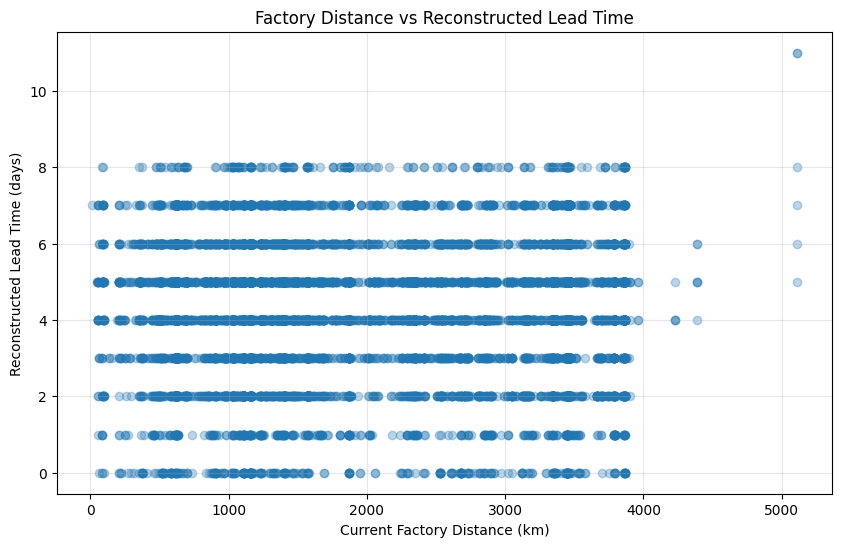

In [ ]:

#  Visualize factory distance versus lead time

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.scatter(
    df_audit["Current Factory Distance (km)"],
    df_audit["Lead Time"],
    alpha=0.3
)

plt.xlabel("Current Factory Distance (km)")
plt.ylabel("Reconstructed Lead Time (days)")
plt.title("Factory Distance vs Reconstructed Lead Time")
plt.grid(True, alpha=0.3)
plt.show()


In [29]:
#: Rank the strongest geographic opportunities

top_opportunities = (
    product_opportunities
    .sort_values("Avg_Distance_Saved_km", ascending=False)
    .head(10)
    .copy()
)

display(
    top_opportunities[
        [
            "Product Name",
            "Current Factory",
            "Best Alternative Factory",
            "Records",
            "Avg_Distance_Saved_km",
            "Avg_Distance_Saved_pct"
        ]
    ].round(2)
)

,Product Name,Current Factory,Best Alternative Factory,Records,Avg_Distance_Saved_km,Avg_Distance_Saved_pct
0,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Lot's O' Nuts,667,2524.35,73.56
1,Wonka Bar - Milk Chocolate,Wicked Choccy's,Lot's O' Nuts,663,2503.00,73.26
2,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Wicked Choccy's,620,2336.66,72.04
3,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Wicked Choccy's,585,2335.04,72.70
4,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Wicked Choccy's,707,2334.83,71.85
5,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Secret Factory,327,2019.21,79.48
6,Fizzy Lifting Drinks,Sugar Shack,Lot's O' Nuts,1,2009.40,95.78
7,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Secret Factory,346,2002.85,79.36
8,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Secret Factory,347,2000.79,80.55
9,Hair Toffee,The Other Factory,Lot's O' Nuts,2,1952.06,85.89


In [30]:
# Check whether each alternative matches the original factory mapping

top_opportunities["Expected Factory"] = (
    top_opportunities["Product Name"].map(product_factory_mapping)
)

top_opportunities["Alternative Matches Mapping"] = (
    top_opportunities["Best Alternative Factory"]
    == top_opportunities["Expected Factory"]
)

display(
    top_opportunities[
        [
            "Product Name",
            "Current Factory",
            "Expected Factory",
            "Best Alternative Factory",
            "Records",
            "Avg_Distance_Saved_km",
            "Alternative Matches Mapping"
        ]
    ].round(2)
)

,Product Name,Current Factory,Expected Factory,Best Alternative Factory,Records,Avg_Distance_Saved_km,Alternative Matches Mapping
0,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Wicked Choccy's,Lot's O' Nuts,667,2524.35,False
1,Wonka Bar - Milk Chocolate,Wicked Choccy's,Wicked Choccy's,Lot's O' Nuts,663,2503.00,False
2,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Lot's O' Nuts,Wicked Choccy's,620,2336.66,False
3,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Lot's O' Nuts,Wicked Choccy's,585,2335.04,False
4,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Lot's O' Nuts,Wicked Choccy's,707,2334.83,False
5,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Lot's O' Nuts,Secret Factory,327,2019.21,False
6,Fizzy Lifting Drinks,Sugar Shack,Sugar Shack,Lot's O' Nuts,1,2009.40,False
7,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Lot's O' Nuts,Secret Factory,346,2002.85,False
8,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Lot's O' Nuts,Secret Factory,347,2000.79,False
9,Hair Toffee,The Other Factory,The Other Factory,Lot's O' Nuts,2,1952.06,False


In [31]:
# Check for valid factory changes under the current mapping

valid_reallocation_options = product_opportunities[
    product_opportunities.apply(
        lambda row: (
            product_factory_mapping.get(row["Product Name"])
            == row["Best Alternative Factory"]
        ),
        axis=1
    )
].copy()

print("Valid alternatives under the existing mapping:", len(valid_reallocation_options))
display(valid_reallocation_options.round(2))

Valid alternatives under the existing mapping: 0


,Product Name,Current Factory,Best Alternative Factory,Records,Avg_Distance_Saved_km,Avg_Distance_Saved_pct,Total_Record_km_Saved


In [32]:
# Summarize geographic reallocation opportunities

total_records = len(df_reallocation)
improved_records = int(df_reallocation["Distance Improvement"].sum())

summary = pd.DataFrame({
    "Metric": [
        "Total records analyzed",
        "Records with a closer alternative factory",
        "Records without a closer alternative",
        "Percentage with a closer alternative",
        "Valid alternatives under current factory mapping"
    ],
    "Value": [
        total_records,
        improved_records,
        total_records - improved_records,
        round(improved_records / total_records * 100, 2),
        len(valid_reallocation_options)
    ]
})

display(summary)

,Metric,Value
0,Total records analyzed,10194.00
1,Records with a closer alternative factory,6967.00
2,Records without a closer alternative,3227.00
3,Percentage with a closer alternative,68.34
4,Valid alternatives under current factory mapping,0.00
